In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')


### Libraries Imported
NumPy, pandas, seaborn and matplotlib loaded; warnings silenced.

In [ ]:
df = pd.read_csv('Student Social Media And Mental Health Impact.csv')

### Dataset Loaded
The Student Social Media and Mental Health Impact CSV was read into `df`.

In [ ]:
df.shape

(5000, 13)

### Dataset Shape
The dataset has 5,000 rows and 13 columns.

In [ ]:
df.columns

Index(['Age', 'Gender', 'Country', 'Academic_Level', 'Most_Used_Platform',
       'Purpose_Of_Use', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks',
       'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night',
       'Stress_Level', 'Mental_Health_Score'],
      dtype='object')

### Column Names Listed
13 columns covering demographics, social media habits, lifestyle, stress level and the target `Mental_Health_Score`.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      5000 non-null   int64  
 1   Gender                   5000 non-null   object 
 2   Country                  5000 non-null   object 
 3   Academic_Level           5000 non-null   object 
 4   Most_Used_Platform       5000 non-null   object 
 5   Purpose_Of_Use           5000 non-null   object 
 6   Avg_Daily_Usage_Hours    5000 non-null   float64
 7   Daily_Unlocks            5000 non-null   int64  
 8   Study_Hours              5000 non-null   float64
 9   Physical_Activity_Hours  5000 non-null   float64
 10  Sleep_Hours_Per_Night    5000 non-null   float64
 11  Stress_Level             5000 non-null   object 
 12  Mental_Health_Score      5000 non-null   float64
dtypes: float64(5), int64(2), object(6)
memory usage: 507.9+ KB


### Data Types and Non-Null Counts
Reviewed the dtype and non-null count of every column.

In [ ]:
df.duplicated().sum()

np.int64(2)

### Duplicate Check
2 duplicate rows were found.

In [ ]:
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,20.82180,5.078460,171.452600,3.008420,1.751000,6.634580,6.230980
std,1.73662,1.653913,42.858254,1.637018,0.668398,1.221391,1.278701
min,18.00000,1.000000,62.000000,0.300000,-0.400000,3.600000,3.600000
25%,19.00000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.00000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.00000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.00000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


### Summary Statistics
Count, mean, spread and quartiles for each numeric column (mean age is about 20.8 and average daily usage about 5.1 hours).

<Axes: xlabel='Mental_Health_Score', ylabel='Count'>

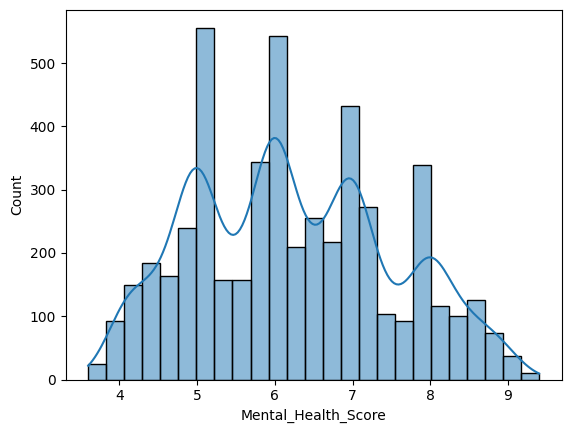

In [ ]:
sns.histplot(df['Mental_Health_Score'],kde=True)

### Mental Health Score Distribution
Histogram with a density curve showing how the target score is spread.

<Axes: >

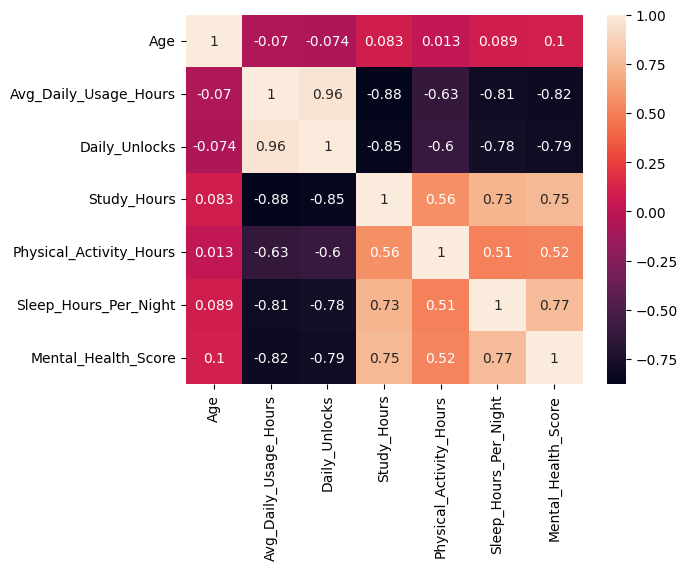

In [ ]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

### Correlation Heatmap
Pairwise correlations between the numeric columns, including the target.

Stress_Level vs Mental Health Score

In [ ]:
order = ['Low','Medium','High','Very High']

### Stress Level Order Defined
Set the order Low, Medium, High, Very High for plotting.

<Axes: xlabel='Stress_Level', ylabel='Mental_Health_Score'>

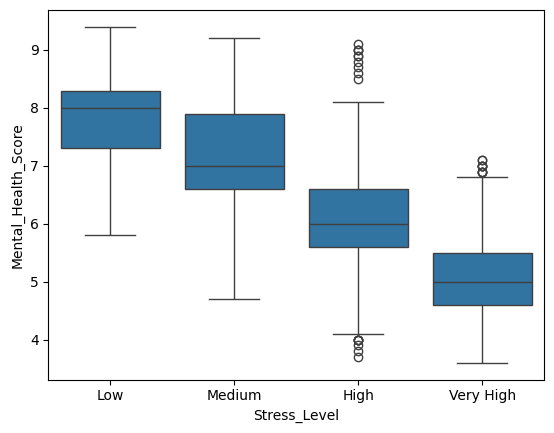

In [ ]:
sns.boxplot(y=df['Mental_Health_Score'],x=df['Stress_Level'],data=df,order=order)

### Score Spread by Stress Level
Box plot comparing mental health scores across the four stress levels.

In [ ]:
df.columns

Index(['Age', 'Gender', 'Country', 'Academic_Level', 'Most_Used_Platform',
       'Purpose_Of_Use', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks',
       'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night',
       'Stress_Level', 'Mental_Health_Score'],
      dtype='object')

### Column Names Rechecked
Printed the columns again before the next plots.

<Axes: xlabel='Avg_Daily_Usage_Hours', ylabel='Mental_Health_Score'>

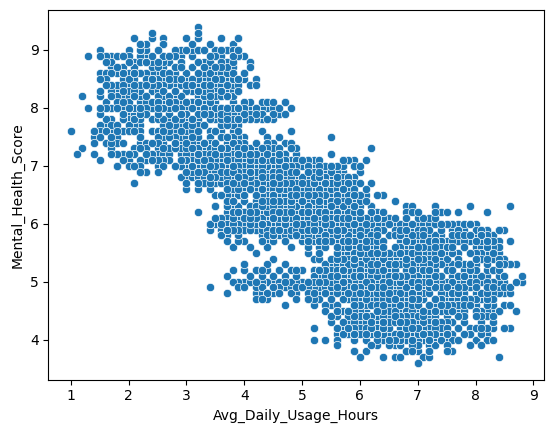

In [ ]:
sns.scatterplot(x=df['Avg_Daily_Usage_Hours'],y=df['Mental_Health_Score'],data=df)

### Screen Time vs Mental Health Score
Scatter plot of average daily usage hours against the score.

<Axes: xlabel='Sleep_Hours_Per_Night', ylabel='Mental_Health_Score'>

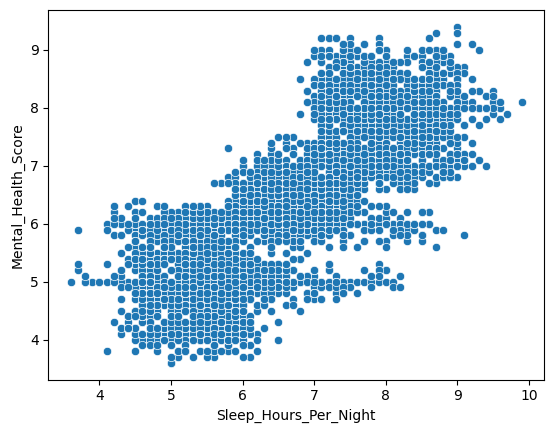

In [ ]:
sns.scatterplot(x=df['Sleep_Hours_Per_Night'],y=df['Mental_Health_Score'],data=df)

### Sleep vs Mental Health Score
Scatter plot of sleep hours per night against the score.

<Axes: xlabel='Most_Used_Platform', ylabel='count'>

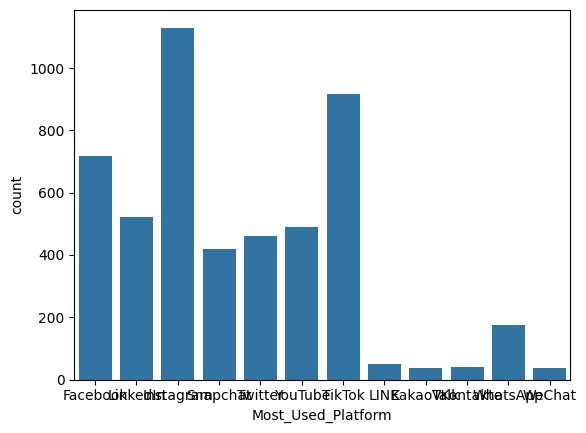

In [ ]:
sns.countplot(data = df,x=df['Most_Used_Platform'])

### Most-Used Platform Counts
Bar chart of how many students use each platform most.

In [ ]:
numeric_cols = df.select_dtypes(include='number')
Q1 = numeric_cols.quantile(0.25)
Q3 = numeric_cols.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = (numeric_cols < lower_bound) | (numeric_cols > upper_bound)

print(outliers.sum())

Age                         0
Avg_Daily_Usage_Hours       0
Daily_Unlocks               0
Study_Hours                 2
Physical_Activity_Hours    22
Sleep_Hours_Per_Night       0
Mental_Health_Score         0
dtype: int64


### Outlier Check (IQR Method)
Flagged 2 outliers in Study_Hours and 22 in Physical_Activity_Hours; the other numeric columns had none.

In [ ]:
df = df.drop_duplicates()
df['Physical_Activity_Hours'] = df['Physical_Activity_Hours'].clip(lower=0)

### Duplicates Removed and Activity Hours Clipped
Dropped the duplicate rows and set any negative Physical_Activity_Hours to 0.

In [ ]:
numeric_cols.skew()

,0
Age,0.155325
Avg_Daily_Usage_Hours,0.005606
Daily_Unlocks,0.002351
Study_Hours,0.435819
Physical_Activity_Hours,0.039971
Sleep_Hours_Per_Night,0.124050
Mental_Health_Score,0.206567


### Skewness Check
Study_Hours is the most skewed feature (about 0.44), so it gets a log transform later.

In [ ]:
top_countries = df['Country'].value_counts().index[:10].tolist()

### Top Countries Selected
Stored the 10 most frequent values of Country.

In [ ]:
top_countries

['Other',
 'India',
 'USA',
 'Canada',
 'Australia',
 'UK',
 'Germany',
 'Mexico',
 'Turkey',
 'France']

### Top Countries Displayed
The list is Other, India, USA, Canada, Australia, UK, Germany, Mexico, Turkey and France.

In [ ]:
def groupCountries(country):
  if country in top_countries:
    return country
  else:
    return 'Other'

### Country Grouping Function Defined
Keeps a country if it is in the top 10 and labels everything else as Other.

In [ ]:
df['Grouped_Country'] = df['Country'].apply(groupCountries)

### Grouped_Country Column Created
Applied the grouping function to build a new `Grouped_Country` column.

In [ ]:
df['Grouped_Country'].value_counts()

,count
Grouped_Country,
Other,3231
India,389
USA,354
Canada,230
Australia,198
UK,185
Germany,136
Mexico,94
Turkey,94


### Grouped Country Counts
Other has 3,231 rows, followed by India (389), USA (354) and Canada (230).

In [ ]:
df.select_dtypes(include='number').sum()

,0
Age,104069.0
Avg_Daily_Usage_Hours,25382.3
Daily_Unlocks,856935.0
Study_Hours,15036.0
Physical_Activity_Hours,8752.3
Sleep_Hours_Per_Night,33160.0
Mental_Health_Score,31143.3


### Numeric Column Totals
Summed each numeric column as a quick sanity check.

In [ ]:
df.columns

Index(['Age', 'Gender', 'Country', 'Academic_Level', 'Most_Used_Platform',
       'Purpose_Of_Use', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks',
       'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night',
       'Stress_Level', 'Mental_Health_Score', 'Grouped_Country'],
      dtype='object')

### Column Names Rechecked
Confirmed the columns, now including `Grouped_Country`.

In [ ]:
skew_feature = ['Study_Hours']
ordinal_feature = ['Stress_Level']
numeric_features = ['Age','Avg_Daily_Usage_Hours','Daily_Unlocks','Physical_Activity_Hours','Sleep_Hours_Per_Night']
one_hot_features = ['Gender', 'Country', 'Academic_Level', 'Most_Used_Platform',
       'Purpose_Of_Use','Grouped_Country']


### Feature Groups Defined
Split features into skewed (Study_Hours), ordinal (Stress_Level), numeric (5 columns) and one-hot (6 categorical columns).

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer,StandardScaler , OrdinalEncoder,OneHotEncoder

skew_columns_pipeline = Pipeline(steps=[
('log_transform',FunctionTransformer(np.log1p)),
('scaler',StandardScaler())
])


ordinal_columns_pipeline = Pipeline(steps=[
('encode',OrdinalEncoder(categories=[['Low','Medium','High','Very High']]))
])


numeric_columns_pipeline = Pipeline(steps=[
('scaler',StandardScaler())
])

one_hot_columns_pipeline = Pipeline(steps=[
('hot_encode',OneHotEncoder(handle_unknown='ignore'))
])


### Preprocessing Pipelines Built
One pipeline each for log + scaling, ordinal encoding, scaling and one-hot encoding.

In [ ]:
input_features = skew_feature + ordinal_feature + numeric_features + one_hot_features

X = df[input_features]
y = df['Mental_Health_Score']

### Features and Target Selected
`X` holds the input features and `y` is Mental_Health_Score.

In [ ]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(transformers = [('skewTransform',skew_columns_pipeline,skew_feature),
('ordinalTransform',ordinal_columns_pipeline,ordinal_feature),
('numericTransform',numeric_columns_pipeline,numeric_features),
('oneHotTransform',one_hot_columns_pipeline,one_hot_features)]
)

### ColumnTransformer Created
Combined the four pipelines into a single preprocessor.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

### Train/Test Split
Data split 70% training and 30% testing with a fixed random state of 42.

In [ ]:
from sklearn.linear_model import LinearRegression
linearRegressorPipeline = Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('linearRegressor',LinearRegression())
])

linearRegressorPipeline.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('skewTransform',
                                                  Pipeline(steps=[('log_transform',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Study_Hours']),
                                                 ('ordinalTransform',
                                                  Pipeline(steps=[('encode',
                                                                   OrdinalEncoder(categories=[['Low',
                                                                                               'Medium',
                                                                                               'High',
                                                                                               'Very '
                                                                                               'High']]))]),
                                                  ['Stress_Level']),
                                                 ('numericTrans...
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['Age',
                                                   'Avg_Daily_Usage_Hours',
                                                   'Daily_Unlocks',
                                                   'Physical_Activity_Hours',
                                                   'Sleep_Hours_Per_Night']),
                                                 ('oneHotTransform',
                                                  Pipeline(steps=[('hot_encode',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Gender', 'Country',
                                                   'Academic_Level',
                                                   'Most_Used_Platform',
                                                   'Purpose_Of_Use',
                                                   'Grouped_Country'])])),
                ('linearRegressor', LinearRegression())])

### Linear Regression Trained
Built a preprocessing + Linear Regression pipeline and fitted it on the training data.

In [ ]:
y_pred_LR = linearRegressorPipeline.predict(X_test)
y_pred_LR_Train = linearRegressorPipeline.predict(X_train)

### Linear Regression Predictions
Generated predictions for the test and training sets.

In [ ]:
from sklearn.metrics import r2_score,mean_squared_error
r2 = r2_score(y_test,y_pred_LR)
r2_training = r2_score(y_train,y_pred_LR_Train)
MSE_LR = mean_squared_error(y_test,y_pred_LR)

### Linear Regression Metrics Calculated
Computed test R², training R² and test MSE.

In [ ]:
print(f'Accuracy with Testing {r2}')
print(f'Accuracy with Training {r2_training}')
print(f'MSE {MSE_LR}')

Accuracy with Testing 0.7866988724615089
Accuracy with Training 0.7800764435193377
MSE 0.37463721913080256


### Linear Regression Results
Test R² is 0.787, training R² is 0.780 and MSE is 0.375, so it fits modestly with no overfitting.

In [ ]:
from sklearn.ensemble import RandomForestRegressor

random_forest_regressor_pipeline = Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('randomForestRegressor',RandomForestRegressor(random_state=42))
])

### Random Forest Pipeline Defined
Built a preprocessing + Random Forest Regressor pipeline.

In [ ]:
random_forest_regressor_pipeline.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('skewTransform',
                                                  Pipeline(steps=[('log_transform',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Study_Hours']),
                                                 ('ordinalTransform',
                                                  Pipeline(steps=[('encode',
                                                                   OrdinalEncoder(categories=[['Low',
                                                                                               'Medium',
                                                                                               'High',
                                                                                               'Very '
                                                                                               'High']]))]),
                                                  ['Stress_Level']),
                                                 ('numericTrans...
                                                  ['Age',
                                                   'Avg_Daily_Usage_Hours',
                                                   'Daily_Unlocks',
                                                   'Physical_Activity_Hours',
                                                   'Sleep_Hours_Per_Night']),
                                                 ('oneHotTransform',
                                                  Pipeline(steps=[('hot_encode',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Gender', 'Country',
                                                   'Academic_Level',
                                                   'Most_Used_Platform',
                                                   'Purpose_Of_Use',
                                                   'Grouped_Country'])])),
                ('randomForestRegressor',
                 RandomForestRegressor(random_state=42))])

### Random Forest Trained
Fitted the Random Forest pipeline on the training data.

In [ ]:
y_pred_RF = random_forest_regressor_pipeline.predict(X_test)
y_pred_RF_Train = random_forest_regressor_pipeline.predict(X_train)

### Random Forest Predictions
Generated predictions for the test and training sets.

In [ ]:
r2 = r2_score(y_test,y_pred_RF)
r2_training = r2_score(y_train,y_pred_RF_Train)
MSE_RF = mean_squared_error(y_test,y_pred_RF)

print(f'Accuracy with Testing {r2}')
print(f'Accuracy with Training {r2_training}')
print(f'MSE {MSE_RF}')

Accuracy with Testing 0.911812336654132
Accuracy with Training 0.986102802284519
MSE 0.1548907937750001


### Random Forest Results
Test R² is 0.912 and MSE is 0.155, much better than Linear Regression, though training R² of 0.986 shows some overfitting.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

random_forest_random_search_cv = RandomizedSearchCV(random_forest_regressor_pipeline,{
    'randomForestRegressor__n_estimators' : [100,200,300],
    'randomForestRegressor__min_samples_split' : [2,5,10],
    'randomForestRegressor__min_samples_leaf' : [1,2,4],
    'randomForestRegressor__max_depth' : [5,10,15]
},
n_iter=15,cv=5,random_state=42,n_jobs=-1,scoring='r2')


### Hyperparameter Search Configured
RandomizedSearchCV over n_estimators, max_depth, min_samples_split and min_samples_leaf (15 combinations, 5-fold CV, scored on R²).

In [ ]:
random_forest_random_search_cv.fit(X_train,y_train)

RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('skewTransform',
                                                                               Pipeline(steps=[('log_transform',
                                                                                                FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                                               ('scaler',
                                                                                                StandardScaler())]),
                                                                               ['Study_Hours']),
                                                                              ('ordinalTransform',
                                                                               Pipeline(steps=[('encode',
                                                                                                OrdinalEncoder(categories=[['Low',
                                                                                                                            'Medium',
                                                                                                                            'High',
                                                                                                                            'Very '
                                                                                                                            'High']]))]...
                                                                                'Grouped_Country'])])),
                                             ('randomForestRegressor',
                                              RandomForestRegressor(random_state=42))]),
                   n_iter=15, n_jobs=-1,
                   param_distributions={'randomForestRegressor__max_depth': [5,
                                                                             10,
                                                                             15],
                                        'randomForestRegressor__min_samples_leaf': [1,
                                                                                    2,
                                                                                    4],
                                        'randomForestRegressor__min_samples_split': [2,
                                                                                     5,
                                                                                     10],
                                        'randomForestRegressor__n_estimators': [100,
                                                                                200,
                                                                                300]},
                   random_state=42, scoring='r2')

### Hyperparameter Search Run
Fitted the search on the training data to find the best settings.

In [ ]:
RF_random_search_best = random_forest_random_search_cv.best_estimator_

### Best Tuned Model Extracted
Saved the best estimator from the search as `RF_random_search_best`.

In [ ]:
y_pred_rf_best = RF_random_search_best.predict(X_test)

### Tuned Model Predictions
Generated test-set predictions from the tuned model.

In [ ]:
r2 = r2_score(y_test,y_pred_rf_best)

MSE_RF_best = mean_squared_error(y_test,y_pred_rf_best)

print(f'Accuracy with Testing {r2}')

print(f'MSE {MSE_RF_best}')

Accuracy with Testing 0.8945905276886419
MSE 0.18513878493045627


### Tuned Model Results
Test R² is 0.895 and MSE is 0.185, slightly below the default Random Forest on this split.

In [ ]:
import joblib

### Joblib Imported
Loaded joblib for saving the model.

In [ ]:
joblib.dump(random_forest_regressor_pipeline,'Mental_Health_Model.pkl')

['Mental_Health_Model.pkl']

### Model Saved
Wrote the default Random Forest pipeline to `Mental_Health_Model.pkl`.

## Final Model Evaluation

All models are compared on the same held-out test set using **R², MSE, RMSE, MAE and Median AE**. RMSE and MAE are in the same units as `Mental_Health_Score`, so they read directly as "points off". A mean-prediction baseline is included for context.

In [ ]:
from sklearn.metrics import (r2_score, mean_squared_error,
                             mean_absolute_error, median_absolute_error)

def evaluate(name, pred_train, pred_test):
    mse_train = mean_squared_error(y_train, pred_train)
    mse_test = mean_squared_error(y_test, pred_test)
    return {
        'Model': name,
        'Train R²': r2_score(y_train, pred_train),
        'Test R²': r2_score(y_test, pred_test),
        'Train RMSE': np.sqrt(mse_train),
        'Test RMSE': np.sqrt(mse_test),
        'Test MSE': mse_test,
        'Test MAE': mean_absolute_error(y_test, pred_test),
        'Test MedAE': median_absolute_error(y_test, pred_test),
    }

models = {
    'Linear Regression': linearRegressorPipeline,
    'Random Forest': random_forest_regressor_pipeline,
    'Random Forest (Tuned)': RF_random_search_best,
}

# Baseline: always predict the training-set mean
mean_value = y_train.mean()
rows = [evaluate('Baseline (mean)',
                 np.full(len(y_train), mean_value),
                 np.full(len(y_test), mean_value))]

for name, model in models.items():
    rows.append(evaluate(name, model.predict(X_train), model.predict(X_test)))

results = pd.DataFrame(rows).set_index('Model')
results['R² Gap (Train - Test)'] = results['Train R²'] - results['Test R²']
results.round(4)

,Train R²,Test R²,Train RMSE,Test RMSE,Test MSE,Test MAE,Test MedAE,R² Gap (Train - Test)
Model,,,,,,,,
Baseline (mean),0.0000,-0.0020,1.2573,1.3266,1.7599,1.1153,1.0867,0.0020
Linear Regression,0.7801,0.7867,0.5896,0.6121,0.3746,0.4787,0.3744,-0.0066
Random Forest,0.9861,0.9118,0.1482,0.3936,0.1549,0.2862,0.2070,0.0743
Random Forest (Tuned),0.9551,0.8946,0.2664,0.4303,0.1851,0.3167,0.2313,0.0605


### Model Comparison Table
Compared the baseline and all three models on R², RMSE, MSE, MAE and Median AE, including the train-test R² gap.

In [ ]:
candidates = results.drop(index='Baseline (mean)')
best_name = candidates['Test RMSE'].idxmin()
best = candidates.loc[best_name]
baseline_rmse = results.loc['Baseline (mean)', 'Test RMSE']

print(f'Best model (lowest Test RMSE): {best_name}')
print(f"  R²   : {best['Test R²']:.4f}")
print(f"  RMSE : {best['Test RMSE']:.4f}")
print(f"  MSE  : {best['Test MSE']:.4f}")
print(f"  MAE  : {best['Test MAE']:.4f}")
print(f"  RMSE improvement over mean baseline: {(1 - best['Test RMSE'] / baseline_rmse) * 100:.1f}%")

Best model (lowest Test RMSE): Random Forest
  R²   : 0.9118
  RMSE : 0.3936
  MSE  : 0.1549
  MAE  : 0.2862
  RMSE improvement over mean baseline: 70.3%


### Best Model Summary
Printed the model with the lowest test RMSE, its scores, and its improvement over the mean baseline.

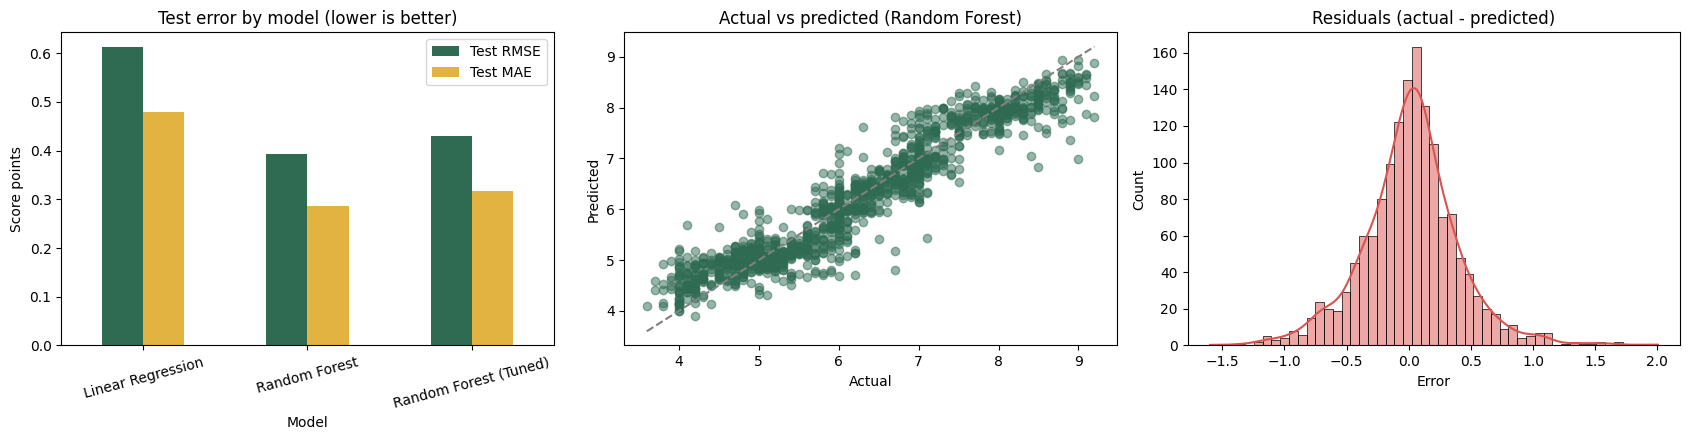

In [ ]:
best_pred = models[best_name].predict(X_test)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

candidates[['Test RMSE', 'Test MAE']].plot.bar(ax=axes[0], rot=15, color=['#2F6B53', '#E3B341'])
axes[0].set_title('Test error by model (lower is better)')
axes[0].set_ylabel('Score points')

axes[1].scatter(y_test, best_pred, alpha=0.5, color='#2F6B53')
lims = [min(y_test.min(), best_pred.min()), max(y_test.max(), best_pred.max())]
axes[1].plot(lims, lims, '--', color='gray')
axes[1].set_title(f'Actual vs predicted ({best_name})')
axes[1].set_xlabel('Actual')
axes[1].set_ylabel('Predicted')

sns.histplot(y_test - best_pred, kde=True, ax=axes[2], color='#D9534F')
axes[2].set_title('Residuals (actual - predicted)')
axes[2].set_xlabel('Error')

plt.tight_layout()
plt.show()

### Evaluation Charts
Bar chart of test RMSE and MAE per model, plus actual vs predicted and residuals for the best model.